# Question 1: Copy-Mutate Algorithm for Cuisine Evolution

### Algorithm Overview & Rubric Compliance:
1. **Epochs & Recipes per Epoch (0.5 mark):** Total recipes ($N = 10,000$) evolved over $E = 10$ epochs. Both epoch count and recipes per epoch are rounded to the nearest integer.
2. **Initialisation of Primordial Cuisine ($t=0$) (0.5 mark):**
   - Recipe size $s$ is set to the rounded average recipe size from Assignment 1.
   - Nature Basket ($NB$) contains all unique ingredients from the Assignment 1 dataset.
   - Number of primordial recipes $N_R^{t=0} = 200$ (within the required $100\text{--}300$ range).
   - Initial Kitchen Basket ($KB$) size is chosen to satisfy $N_R^{t=0} \gg |KB|$ ($|KB_0| = 50$) and expands proportionally from the Nature Basket across epochs to maintain the Kitchen-to-Nature Basket size ratio.
3. **Copy-Mutate Implementation (3 marks):** Randomly selects a recipe from the kitchen, picks a random ingredient from the recipe and one from the Kitchen Basket ($KB$), replaces the recipe ingredient if they differ (ensuring no duplicate ingredients within a recipe), and adds the mutated recipe to the cuisine if it is unique.
4. **Epoch-wise & Multi-Instance Evaluation (5 marks):** Plots recipe size and normalized frequency-rank distributions for each epoch, and evaluates statistics across 5 independent instances of cuisine evolution.

Average Recipe Size (s): 9
Total Target Recipes: 10000
Number of Epochs (rounded): 10
Number of Recipes per Epoch (rounded): 980
Primordial Recipes at t=0 (N_R^t=0): 200
Initial Kitchen Basket Size: 50 (N_R^t=0 >> Size of KB)
Nature Basket Size: 13801

Running Epoch-tracking simulation...


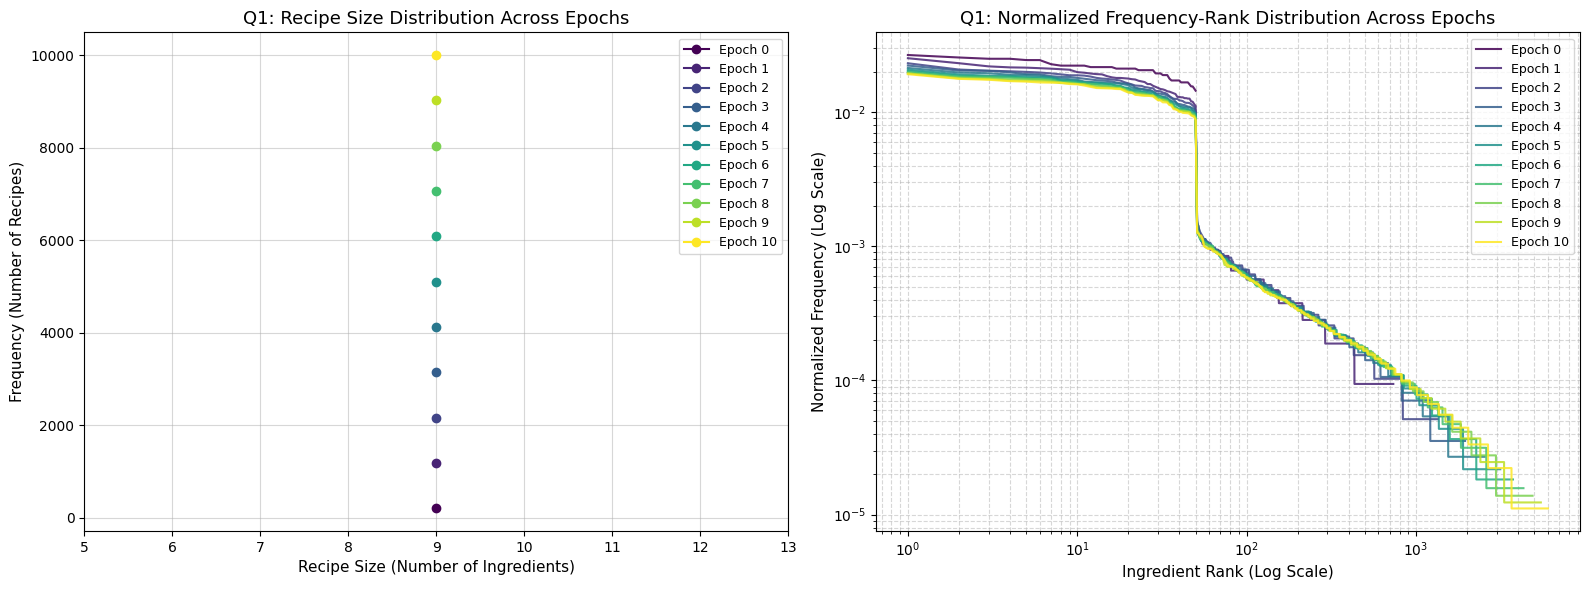


Running 5 independent instances of cuisine evolution...
Instance 1/5 complete: 10000 unique recipes generated.
Instance 2/5 complete: 10000 unique recipes generated.
Instance 3/5 complete: 10000 unique recipes generated.
Instance 4/5 complete: 10000 unique recipes generated.
Instance 5/5 complete: 10000 unique recipes generated.


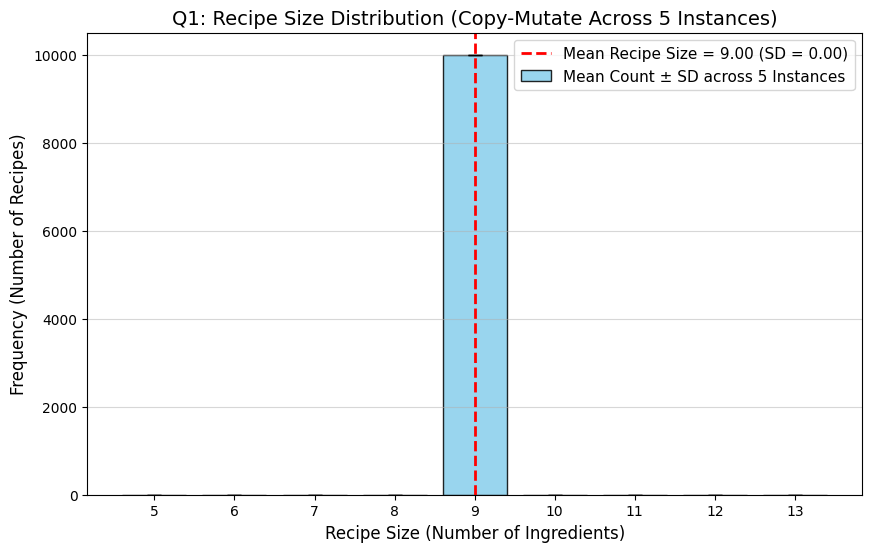

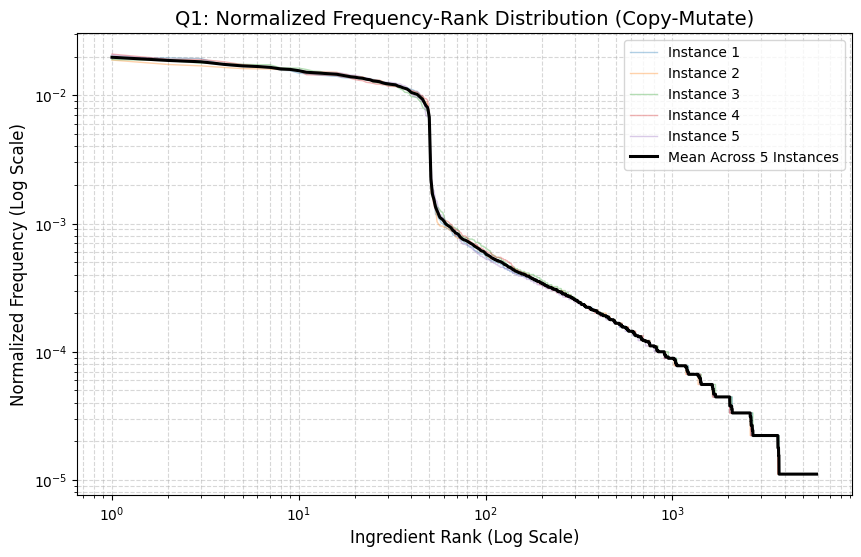

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import Counter

# ==========================================
# 1. Load Data & Compute Empirical Parameters
# ==========================================
df_raw = pd.read_csv("1b_extracted_ingredients.csv")
df_raw['Ingredient Name'] = df_raw['Ingredient Name'].fillna("").astype(str).str.strip()
df_raw = df_raw[df_raw['Ingredient Name'] != ""]

# Recipe size s (rounded to nearest integer as obtained in Assignment 1 Q2b)
empirical_recipe_sizes = df_raw.groupby('Recipe ID').size()
s = int(round(empirical_recipe_sizes.mean()))
total_target_recipes = int(empirical_recipe_sizes.shape[0])

# Nature Basket (NB): All unique ingredients from dataset
nature_basket = list(df_raw['Ingredient Name'].unique())
size_nb = len(nature_basket)

# ==========================================
# 2. Define Epochs & Recipes per Epoch (0.5 mark)
# ==========================================
num_epochs = int(round(10))
n_r_t0 = int(round(200))  # Primordial recipes at t=0 (100-300 range)
recipes_per_epoch = int(round((total_target_recipes - n_r_t0) / num_epochs))

# Kitchen Basket (KB) initial size: N_R^{t=0} >> Size of KB
initial_kb_size = int(round(50))  # 200 >> 50
# Incremental KB expansion per epoch to maintain Kitchen-to-Nature Basket ratio
kb_step_per_epoch = int(round((size_nb - initial_kb_size) / num_epochs))

print(f"Average Recipe Size (s): {s}")
print(f"Total Target Recipes: {total_target_recipes}")
print(f"Number of Epochs (rounded): {num_epochs}")
print(f"Number of Recipes per Epoch (rounded): {recipes_per_epoch}")
print(f"Primordial Recipes at t=0 (N_R^t=0): {n_r_t0}")
print(f"Initial Kitchen Basket Size: {initial_kb_size} (N_R^t=0 >> Size of KB)")
print(f"Nature Basket Size: {size_nb}")

# ==========================================
# 3. Primordial Cuisine & Copy-Mutate Algorithm (3.5 marks)
# ==========================================
def initialize_primordial_cuisine(nb, n_r_0, recipe_size, kb_0_size):
    """Initializes primordial cuisine (t=0), Nature Basket (NB), and Kitchen Basket (KB)."""
    shuffled_nb = nb.copy()
    random.shuffle(shuffled_nb)

    # Kitchen Basket initialized from Nature Basket
    kb = shuffled_nb[:kb_0_size]
    remaining_nb = shuffled_nb[kb_0_size:]

    cuisine_list = []
    cuisine_set = set()

    while len(cuisine_list) < n_r_0:
        recipe = sorted(random.sample(kb, recipe_size))
        recipe_key = frozenset(recipe)
        if recipe_key not in cuisine_set:
            cuisine_set.add(recipe_key)
            cuisine_list.append(recipe)

    return cuisine_list, cuisine_set, kb, remaining_nb

def copy_mutate_recipe(cuisine_list, kb):
    """Steps 3-7: Pick a random recipe and mutate one ingredient using KB."""
    chosen_recipe = random.choice(cuisine_list).copy()
    recipe_ing_set = set(chosen_recipe)

    # Repeat Steps 4-5 until the recipe gets modified
    while True:
        idx_to_replace = random.randrange(len(chosen_recipe))
        rec_ing = chosen_recipe[idx_to_replace]
        kb_ing = random.choice(kb)

        # Compare ingredients: replace if different and not already in the recipe
        if kb_ing != rec_ing and kb_ing not in recipe_ing_set:
            chosen_recipe[idx_to_replace] = kb_ing
            break

    return chosen_recipe

def run_copy_mutate_simulation(record_epochs=False):
    """Runs a full evolution across all epochs."""
    cuisine_list, cuisine_set, kb, remaining_nb = initialize_primordial_cuisine(
        nature_basket, n_r_t0, s, initial_kb_size
    )

    epoch_history = {}
    if record_epochs:
        epoch_history[0] = [r.copy() for r in cuisine_list]

    for epoch in range(1, num_epochs + 1):
        # Maintain Kitchen-to-Nature Basket ratio as cuisine grows
        if remaining_nb:
            add_count = min(kb_step_per_epoch, len(remaining_nb))
            kb.extend(remaining_nb[:add_count])
            remaining_nb = remaining_nb[add_count:]

        target_count = n_r_t0 + epoch * recipes_per_epoch

        # Step 9: Repeat Steps 3-7 until number of recipes reaches desired number for next Epoch
        while len(cuisine_list) < target_count:
            new_recipe = copy_mutate_recipe(cuisine_list, kb)
            recipe_key = frozenset(new_recipe)
            # Step 8: Add modified/mutated recipe if not already present
            if recipe_key not in cuisine_set:
                cuisine_set.add(recipe_key)
                cuisine_list.append(new_recipe)

        if record_epochs:
            epoch_history[epoch] = [r.copy() for r in cuisine_list]

    return cuisine_list, epoch_history

# ==========================================
# 4. Plot Recipe Size & Normalized Freq-Rank per Epoch (1 mark)
# ==========================================
print("\nRunning Epoch-tracking simulation...")
_, epoch_snapshots = run_copy_mutate_simulation(record_epochs=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
cmap = plt.cm.viridis(np.linspace(0, 1, len(epoch_snapshots)))

for idx, (ep, recipes_ep) in enumerate(epoch_snapshots.items()):
    # Recipe sizes at epoch ep
    sizes_ep = [len(r) for r in recipes_ep]
    size_counts = Counter(sizes_ep)
    axes[0].plot(list(size_counts.keys()), list(size_counts.values()), marker='o', color=cmap[idx], label=f'Epoch {ep}')

    # Normalized frequency-rank at epoch ep
    all_ings = [ing for r in recipes_ep for ing in r]
    ing_counts = np.array(sorted(Counter(all_ings).values(), reverse=True))
    norm_freqs = ing_counts / ing_counts.sum()
    ranks = np.arange(1, len(norm_freqs) + 1)
    axes[1].loglog(ranks, norm_freqs, color=cmap[idx], alpha=0.85, label=f'Epoch {ep}')

axes[0].set_title('Q1: Recipe Size Distribution Across Epochs', fontsize=13)
axes[0].set_xlabel('Recipe Size (Number of Ingredients)', fontsize=11)
axes[0].set_ylabel('Frequency (Number of Recipes)', fontsize=11)
axes[0].set_xticks(range(max(1, s - 4), s + 5))
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.5)

axes[1].set_title('Q1: Normalized Frequency-Rank Distribution Across Epochs', fontsize=13)
axes[1].set_xlabel('Ingredient Rank (Log Scale)', fontsize=11)
axes[1].set_ylabel('Normalized Frequency (Log Scale)', fontsize=11)
axes[1].legend(fontsize=9)
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("Q1_Epoch_Wise_Recipe_Size_and_Normalized_Frequency_Rank_Distribution.png", dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 5. Run 5 Instances of Cuisine Evolution (2.5 marks)
# ==========================================
num_instances = 5
instance_sizes_list = []
instance_norm_freqs = []

print(f"\nRunning {num_instances} independent instances of cuisine evolution...")
for inst in range(num_instances):
    final_cuisine, _ = run_copy_mutate_simulation(record_epochs=False)

    # Collect recipe sizes
    sizes = [len(r) for r in final_cuisine]
    instance_sizes_list.append(sizes)

    # Collect normalized ingredient frequencies
    all_ings = [ing for r in final_cuisine for ing in r]
    counts = np.array(sorted(Counter(all_ings).values(), reverse=True))
    norm_freq = counts / counts.sum()
    instance_norm_freqs.append(norm_freq)
    print(f"Instance {inst+1}/{num_instances} complete: {len(final_cuisine)} unique recipes generated.")

# ==========================================
# 6. Plot Recipe Size Distribution with Mean & SD (1.5 marks)
# ==========================================
all_sizes_flat = np.concatenate(instance_sizes_list)
mean_size = np.mean(all_sizes_flat)
std_size = np.std(all_sizes_flat)

min_s, max_s = max(1, s - 4), s + 4
size_range = np.arange(min_s, max_s + 1)
size_matrix = np.zeros((num_instances, len(size_range)))

for i, sizes in enumerate(instance_sizes_list):
    c = Counter(sizes)
    for j, val in enumerate(size_range):
        size_matrix[i, j] = c.get(val, 0)

mean_counts = size_matrix.mean(axis=0)
std_counts = size_matrix.std(axis=0)

plt.figure(figsize=(10, 6))
plt.bar(size_range, mean_counts, yerr=std_counts, capsize=5, color='skyblue', edgecolor='black', alpha=0.85, label='Mean Count ± SD across 5 Instances')
plt.axvline(mean_size, color='red', linestyle='--', linewidth=2, label=f'Mean Recipe Size = {mean_size:.2f} (SD = {std_size:.2f})')
plt.title('Q1: Recipe Size Distribution (Copy-Mutate Across 5 Instances)', fontsize=14)
plt.xlabel('Recipe Size (Number of Ingredients)', fontsize=12)
plt.ylabel('Frequency (Number of Recipes)', fontsize=12)
plt.xticks(size_range)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.5)
plt.savefig("Q1_Recipe_Size_Distribution.png", dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 7. Plot Normalized Frequency-Rank Distribution (1 mark)
# ==========================================
plt.figure(figsize=(10, 6))
min_ranks = min(len(nf) for nf in instance_norm_freqs)
freq_matrix = np.array([nf[:min_ranks] for nf in instance_norm_freqs])
ranks = np.arange(1, min_ranks + 1)

for i in range(num_instances):
    plt.loglog(ranks, freq_matrix[i], alpha=0.35, linewidth=1, label=f'Instance {i+1}')

mean_freq_curve = freq_matrix.mean(axis=0)
plt.loglog(ranks, mean_freq_curve, color='black', linewidth=2.2, label='Mean Across 5 Instances')

plt.title('Q1: Normalized Frequency-Rank Distribution (Copy-Mutate)', fontsize=14)
plt.xlabel('Ingredient Rank (Log Scale)', fontsize=12)
plt.ylabel('Normalized Frequency (Log Scale)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.savefig("Q1_Normalized_Frequency_Rank_Distribution.png", dpi=300, bbox_inches='tight')
plt.show()